# Тема 3. Быстрые треки в плейлистах Spotify

Хочу узнать, как часто попадаются треки с темпом от 130 BPM в плейлистах разных жанров. Например, какой шанс выбрать быстрый трек из рэп-плейлиста?

![Енот в больших наушниках слушает музыку в магазине пластинок.](enot_v_naushnikah.png)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Данные

Плейлисты Spotify, 32 833 строки.

- `track_id` — код трека.
- `playlist_genre` — жанр плейлиста.
- `tempo` — темп в BPM.

Темп выше нуля. Одна строка на пару «трек — жанр».

[TidyTuesday — Spotify Songs](https://github.com/rfordatascience/tidytuesday/blob/main/data/2020/2020-01-21/readme.md)

In [2]:
pesni = pd.read_csv('spotify_tempo.csv')
print(f'Строк в файле: {len(pesni)}')
pesni = pesni[pesni['tempo'] > 0].drop_duplicates(['track_id', 'playlist_genre'])
print(f'Строк после очистки: {len(pesni)}')
display(pesni.head())

Строк в файле: 32833
Строк после очистки: 30384


,track_id,playlist_genre,tempo
0,6f807x0ima9a1j3VPbc7VN,pop,122.036
1,0r7CVbZTWZgbTCYdfa2P31,pop,99.972
2,1z1Hg7Vb0AhHDiEmnDE79l,pop,124.008
3,75FpbthrwQmzHlBJLuGdC7,pop,121.956
4,1e8PAfcKUYoKkxPhrHqw4x,pop,123.976


## 2. Условная вероятность

$A$ — темп ≥ 130 BPM. $B$ — трек из плейлиста выбранного жанра.

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}=\frac{\text{быстрых треков в жанре}}{\text{всех треков в жанре}}.$$

In [3]:
pesni = pesni.assign(bystro=pesni['tempo'] >= 130)
stroki = []
for zhanr in pesni['playlist_genre'].unique():
    gruppa = pesni[pesni['playlist_genre'] == zhanr]
    bystro = gruppa['bystro'].sum()
    stroki.append([zhanr, bystro, len(gruppa), bystro / len(gruppa)])

tab = pd.DataFrame(stroki, columns=['Жанр', 'Быстрых', 'Всего', 'Доля'])
tab = tab.sort_values('Доля', ascending=False).reset_index(drop=True)
display(tab.round(3))
print(f'По всей таблице: {pesni["bystro"].mean():.1%}')

,Жанр,Быстрых,Всего,Доля
0,rap,2257,5486,0.411
1,rock,1796,4450,0.404
2,pop,1365,5132,0.266
3,r&b,1262,5138,0.246
4,latin,1086,4641,0.234
5,edm,932,5537,0.168


По всей таблице: 28.6%


## 3. Сравнение жанров

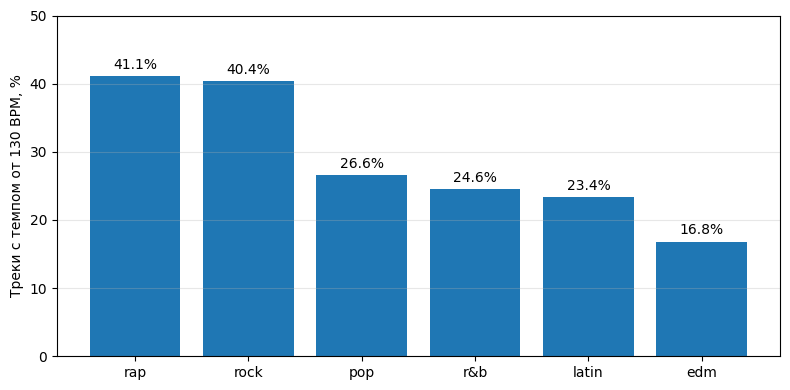

In [4]:
plt.figure(figsize=(8, 4))
stolb = plt.bar(tab['Жанр'], tab['Доля'] * 100, color='tab:blue')
plt.bar_label(stolb, fmt='%.1f%%', padding=3)
plt.ylabel('Треки с темпом от 130 BPM, %')
plt.ylim(0, 50)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()